In [6]:
import hashlib
import os
import platform
import uuid

# 修改为自己的学号
STUDENT_ID = 20244081117

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]     {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

[Conda 环境] py_dateprocessing
[学号]     20244081117
[机器指纹] c8328ad6c13c29ec
[RUN_ID]   20244081117-c8328ad6c13c29ec


围绕半圆定律

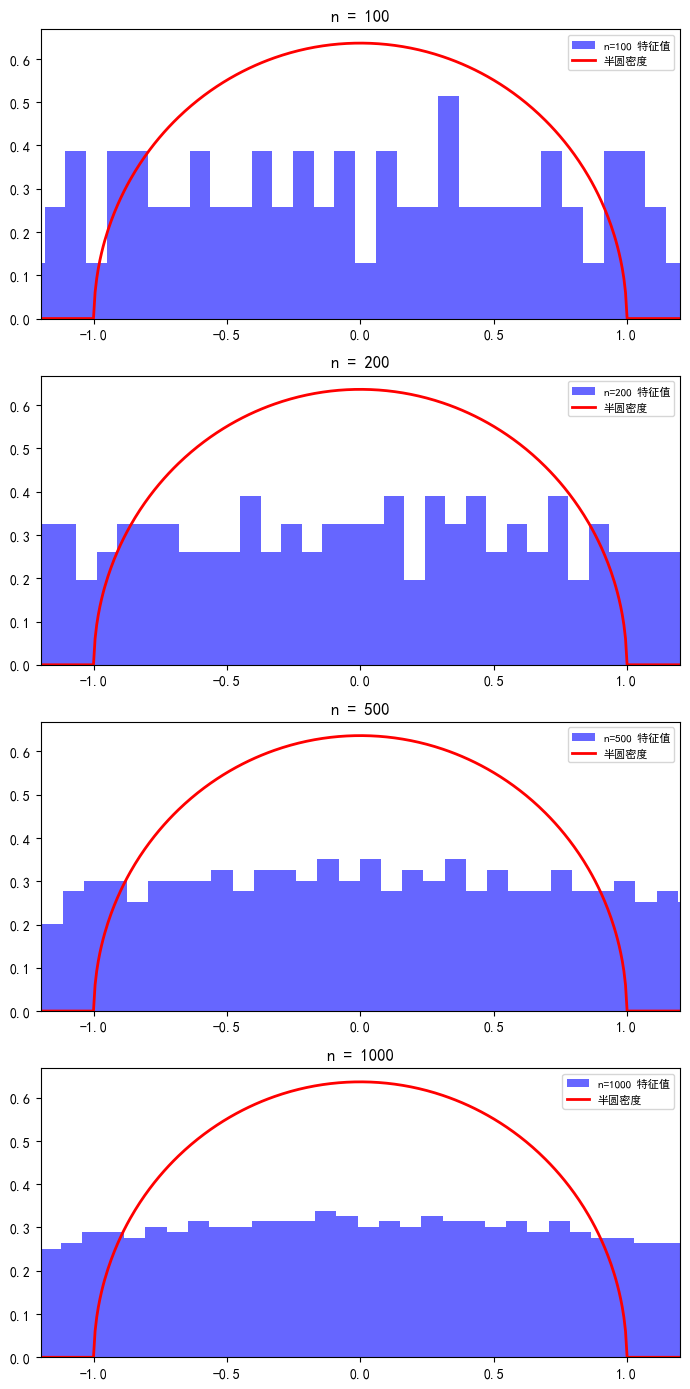

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

# ---- 中文显示配置（放在最前面）----
matplotlib.rcParams["font.sans-serif"] = ["SimHei", "Microsoft YaHei", "SimSun", "DejaVu Sans"]
matplotlib.rcParams["axes.unicode_minus"] = False

def wigner_density(x):
    x = np.asarray(x, dtype=float)
    density = np.where(np.abs(x) <= 1,
                       (2 / np.pi) * np.sqrt(np.maximum(0.0, 1 - x ** 2)),
                       0.0)
    if density.ndim == 0:
        return float(density)
    return density


def generate_wigner(n):
    if not isinstance(n, (int, np.integer)) or isinstance(n, bool):
        raise TypeError("n 必须是整数")
    if n <= 0:
        raise ValueError("n 必须是正整数")
    upper = np.random.normal(0.0, np.sqrt(1.0 / n), size=(n, n))
    z = np.triu(upper)
    z = z + z.T - np.diag(np.diag(z))
    return z


def get_spectrum(matrix):
    eigvals = np.linalg.eigvalsh(np.asarray(matrix))
    return np.sort(eigvals)


ns = [100, 200, 500, 1000]
fig, axes = plt.subplots(4, 1, figsize=(7, 14))
x_grid = np.linspace(-1.2, 1.2, 400)

for ax, n in zip(axes, ns):
    Z = generate_wigner(n)
    eigvals = get_spectrum(Z)
    ax.hist(eigvals, bins=50, density=True, color="blue", alpha=0.6,
            label=f"n={n} 特征值")
    ax.plot(x_grid, wigner_density(x_grid), color="red", linewidth=2,
            label="半圆密度")
    ax.set_xlim(-1.2, 1.2)
    ax.set_title(f"n = {n}")
    ax.legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()

Conway 的生命游戏

In [8]:
def is_valid_board(board):
    """有效棋盘：二维 ndarray"""
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    return bool(np.all((board == 0) | (board == 1)))


def gol_step(board):
    """返回下一步棋盘"""
    if not is_valid_board(board):
        raise ValueError("无效棋盘：必须是元素仅为 0/1 的二维 ndarray")

    m, n = board.shape
    neighbors = np.zeros((m, n), dtype=int)
    for di in (-1, 0, 1):
        for dj in (-1, 0, 1):
            if di == 0 and dj == 0:
                continue
            neighbors += np.roll(np.roll(board, di, axis=0), dj, axis=1)

    new_board = np.zeros((m, n), dtype=int)
    survive = (board == 1) & ((neighbors == 2) | (neighbors == 3))
    born = (board == 0) & (neighbors == 3)
    new_board[survive | born] = 1
    return new_board


def draw_gol_board(board):
    """
    将棋盘画成 m×n 个方格
    """
    
    fig, ax = plt.subplots(figsize=(4, 4))
    
    #0 为白色，1 为黑色
    ax.imshow(board, cmap="binary", interpolation="nearest")
    ax.set_xticks([])
    ax.set_yticks([])
    plt.tight_layout()
    plt.show()

测试函数

初始棋盘:
[[0 0 0 0 0 0]
 [0 0 1 0 0 0]
 [0 0 0 1 0 0]
 [0 1 1 1 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]]


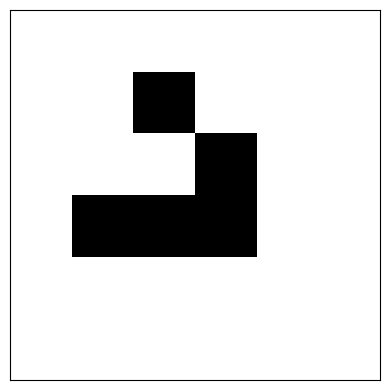


下一步:
[[0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 1 0 1 0 0]
 [0 0 1 1 0 0]
 [0 0 1 0 0 0]
 [0 0 0 0 0 0]]


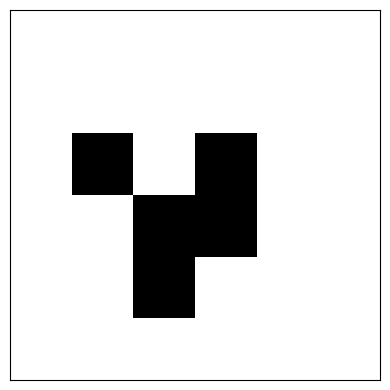


测试边界环绕，演化后的棋盘:
[[1 1 1]
 [1 1 1]
 [1 1 1]]


In [9]:
import numpy as np

board = np.zeros((6, 6), dtype=int)
board[1, 2] = 1
board[2, 3] = 1
board[3, 1] = board[3, 2] = board[3, 3] = 1

print("初始棋盘:")
print(board)
draw_gol_board(board)

next_board = gol_step(board)
print("\n下一步:")
print(next_board)
draw_gol_board(next_board)

test_board = np.zeros((3, 3), dtype=int)
test_board[2, 2] = 1
test_board[2, 0] = 1
test_board[0, 2] = 1

print("\n测试边界环绕，演化后的棋盘:")
print(gol_step(test_board))

pandas DataFrame（iris_corrected .csv在hw03_data内）

In [10]:
import pandas as pd
import numpy as np

# ================= 1. 读取数据与基础信息 =================
df = pd.read_csv("hw03_data/iris.csv", index_col=0)

print("=== 数据集基本信息 ===")
print(f"数据点数量: {len(df)}")
print(f"原始列名: {df.columns.tolist()}")
print(f"各列数据类型:\n{df.dtypes}")


df["species"] = ["setosa"] * 50 + ["versicolor"] * 50 + ["virginica"] * 50
print(f"\n已手动补充种类列，花卉种类数: {df['species'].nunique()}")
print(f"花卉种类: {df['species'].unique().tolist()}")


# ================= 2. 修正第 35 和 38 行 =================
col_sepal_len = "sepal length (cm)"
col_sepal_wid = "sepal width (cm)"
col_petal_len = "petal length (cm)"
col_petal_wid = "petal width (cm)"

print("\n=== 修正前第 35 行（索引 34）和 第 38 行（索引 37） ===")
print(df.loc[[34, 37]])

df.loc[34, col_sepal_len] = 4.9
df.loc[34, col_sepal_wid] = 3.1
df.loc[34, col_petal_len] = 1.5
df.loc[34, col_petal_wid] = 0.2
df.loc[34, "species"] = "setosa"

df.loc[37, col_sepal_len] = 4.9
df.loc[37, col_sepal_wid] = 3.6
df.loc[37, col_petal_len] = 1.4
df.loc[37, col_petal_wid] = 0.1
df.loc[37, "species"] = "setosa"

print("\n=== 修正后 ===")
print(df.loc[[34, 37]])


# ================= 3. 添加两个新特征列 =================
df["Petal.Ratio"] = df[col_petal_len] / df[col_petal_wid]
df["Sepal.Ratio"] = df[col_sepal_len] / df[col_sepal_wid]

print("\n=== 添加新列后的前 5 行 ===")
print(df.head())


# ================= 4. 保存为 iris_corrected.csv =================
df.to_csv("hw03_data/iris_corrected.csv", index=False)
print("\n✅ 已成功保存到 hw03_data/iris_corrected.csv")


# ================= 5. 按花卉种类分组汇总 =================
summary = df.groupby("species")[["Petal.Ratio", "Sepal.Ratio"]].agg(
    ["mean", "median", "min", "max", "std"]
)

print("\n=== 分组汇总统计 ===")
print(summary)

=== 数据集基本信息 ===
数据点数量: 150
原始列名: ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']
各列数据类型:
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species           object
dtype: object

已手动补充种类列，花卉种类数: 3
花卉种类: ['setosa', 'versicolor', 'virginica']

=== 修正前第 35 行（索引 34）和 第 38 行（索引 37） ===
    SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species  \
Id                                                                          
34            5.5           4.2            1.4           0.2  Iris-setosa   
37            5.5           3.5            1.3           0.2  Iris-setosa   

   species  
Id          
34  setosa  
37  setosa  

=== 修正后 ===
    SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species  \
Id                                                                          
34            5.5           4.2            1.4           0.2  Iris-setosa   
37            5.5           3.5  